In [ ]:
import pandas as pd
import tqdm
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import json
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Filtering english texts

In [ ]:
data_onlyen=pd.read_csv('/content/drive/MyDrive/gwenEU/dataenglishv2.csv.gzip',compression='gzip',low_memory=False)

In [ ]:
print(data_onlyen['language'].value_counts())
sum(data_onlyen['language'].value_counts())

language
en    332577
EN      8194
Name: count, dtype: int64


340771

/tmp/ipython-input-1623553095.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_onlyen['pubdate'] = pd.to_datetime(data_onlyen['pubdate'])


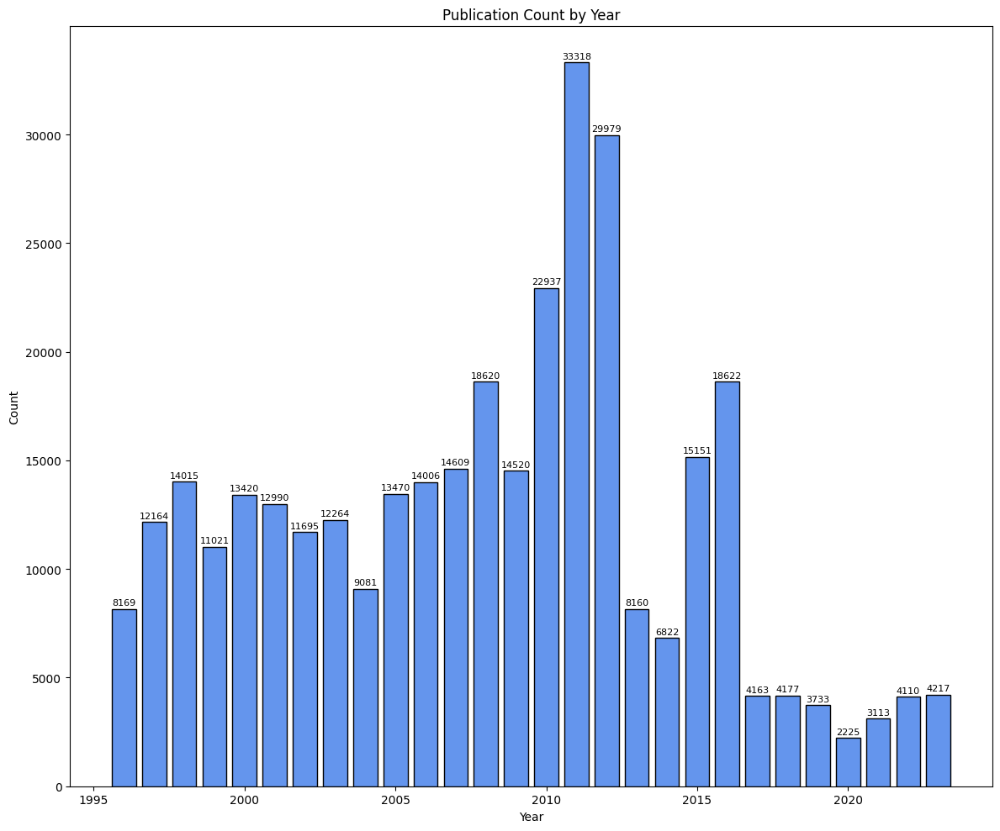

In [ ]:
data_onlyen['pubdate'] = pd.to_datetime(data_onlyen['pubdate'])
year_counts = data_onlyen['pubdate'].dt.year.value_counts().sort_index()

plt.figure(figsize=(12,10))
bars = plt.bar(year_counts.index, year_counts.values, color='cornflowerblue', edgecolor='black')
for i, count in enumerate(year_counts.values):
    plt.text(year_counts.index[i], count + 100, str(count), ha='center', va='bottom', fontsize=8)

plt.xlabel('Year')
plt.ylabel('Count')
plt.title('Publication Count by Year')
plt.tight_layout()

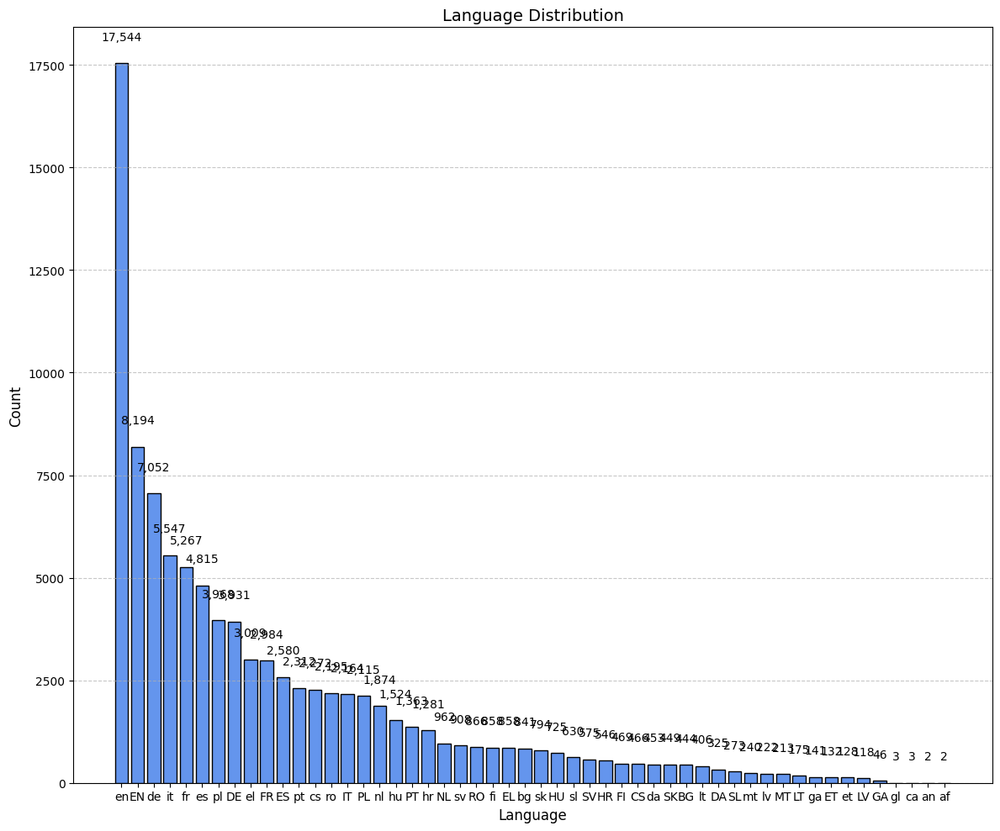

95264


In [ ]:
# Count the occurrences of each language
lang_counts = data_filter['language'].value_counts()

plt.figure(figsize=(12,10))

# Bar chart
bars = plt.bar(lang_counts.index, lang_counts.values, color='cornflowerblue', edgecolor='black')

# Add value labels above bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 500, f'{yval:,}', ha='center', va='bottom', fontsize=10)

# Title and labels
plt.title('Language Distribution', fontsize=14)
plt.xlabel('Language', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(sum(lang_counts))

In [ ]:
import re
import string
replace_punct = re.compile('[%s]' % re.escape(string.punctuation))
def simplify_text(text):
    """
    Simplify text by lower casing and removing all punctuation and excess spaces
    :param text: a string (a congressional speech)
    :return: a cleaned up string
    """
    # drop all punctuation
    text = replace_punct.sub('', text)
    # lower case the text
    text = text.strip().lower()
    # convert all white space spans to single spaces
    text = re.sub(r'\s+', ' ', text)
    return text

In [ ]:
# Drop rows where 'description' has less than 3 words or fewer than 16 characters
data3 = data_onlyen[data_onlyen['description'].apply(lambda x: isinstance(x, str) and len(x.split()) >= 3 and len(x) >= 16)]

In [ ]:
data3 = data3.copy()
data3['description'] = data3['description'].apply(simplify_text)

In [ ]:
data3.to_csv('/content/drive/MyDrive/gwenEU/dataenglishv3.csv.gzip', index=False, compression='gzip')

#Preparation of the training and the validation data

In [ ]:
#We then identify speeches shorter than 200 characters, and keep those that are repeated verbatim at least 20 times as positive examples of
#procedural speeches, and put a random 10% of these into the training data. (We only use 10%—giving each unique text string an equal chance of being
#selected, no matter how many times it occurs—due to the massive number of such speeches).

from collections import Counter

speech_counter = Counter()
long_pieces = []
id_count = 0

for index, row in data3.iterrows():
    speech_id = row['guid']
    text = row['description']
    tokens = text.split()

    if len(text) < 200:
        speech_counter[text] += 1
    elif len(text) > 1000 and len(tokens) > 20:
        n_pieces = (len(text) // 200) + 1
        n_tokens = len(tokens)
        n_tokens_per_piece = n_tokens // n_pieces

        for n in range(n_pieces):
            if n < n_pieces - 1:
                subset = tokens[n * n_tokens_per_piece: (n+1) * n_tokens_per_piece]
            else:
                subset = tokens[n * n_tokens_per_piece:]
            segment_length = len(' '.join(subset))
            if segment_length < 1000:
                outline = {'id': 'x' + str(id_count).zfill(8), 'tokens': [subset], 'procedural': 'no'}
                long_pieces.append(outline)
                id_count += 1

In [ ]:
from pprint import pprint
pprint(speech_counter.most_common(10))

[('oral explanations of vote', 439),
 ('before the vote', 302),
 ('– before the vote', 260),
 ('written explanations of vote', 143),
 ('president – the debate is closed the vote will take place tomorrow at 12 '
  'noon',
  137),
 ('president – the debate is closed written statements rule 149', 115),
 ('president – the debate is closed', 109),
 ('president – the minutes of yesterdays sitting have been distributed are '
  'there any comments',
  90),
 ('president – that concludes the vote', 84),
 ('president – thank you commissioner the debate is closed the vote will take '
  'place tomorrow at 12 noon',
  61)]


In [ ]:
train_lines=[]
test_lines=[]
# randomly assign non-procedural speeches to train or test
# down-sample non-procedural speech pieces by a factor of 50 (heuristically chosen to balance)
random_indices = np.random.choice(np.arange(len(long_pieces)), size=len(long_pieces)//50, replace=False)
# select a random test set of 5% of pieces
test_indices = np.random.choice(random_indices, size=len(random_indices)//20, replace=False)
# use the remainder as train
train_indices = list(set(random_indices) - set(test_indices))
for index in train_indices:
    train_lines.append(long_pieces[index])
for index in test_indices:
    test_lines.append(long_pieces[index])

In [ ]:
# assign 1/10th of the short speeches into train and test, assigned to the procedural = yes category
n = 0
for text, count in tqdm(speech_counter.items()):
    # put those that only occur between 10 and 20 times into test data (once)
    if 10 <= count < 20:
        outline = {'id': 'se' + str(n).zfill(8), 'tokens': [text.split()], 'procedural': 'yes'}
        test_lines.append(outline)
        n += 1
        # put those that occur at least 20 times into train (duplicated by a factor of 1/10)
    elif count >= 20:
        for c in range(count//10):
            outline = {'id': 'st' + str(n).zfill(8), 'tokens': [text.split()], 'procedural': 'yes'}
            train_lines.append(outline)
            n += 1
print("Saving train and test lines")
print(len(train_lines), len(test_lines))
# randomly shuffle the train and test set and write them to files
outfile = os.path.join('/content/drive/MyDrive/gwenEU/', 'short_vs_long_trainenglish.jsonlist')
random.shuffle(train_lines)
with open(outfile, 'w') as f:
    for line in train_lines:
        f.write(json.dumps(line) + '\n')
outfile = os.path.join('/content/drive/MyDrive/gwenEU/', 'short_vs_long_testenglish.jsonlist')
random.shuffle(test_lines)
with open(outfile, 'w') as f:
    for line in test_lines:
        f.write(json.dumps(line) + '\n')

100%|██████████| 20490/20490 [00:00<00:00, 1433860.37it/s]


Saving train and test lines
42635 2445


In [ ]:
shortish_speeches = []
for index, row in data3.iterrows():
    speech_id = line['id']
    tokens = []
    for sent in line['tokens']:
        tokens.extend(sent)
    text = ' '.join(tokens)
    # drop punctuation and convert to lower case
    text = simplify_text(text)
    tokens = text.split()
    # skip very short speeches altogether
    if len(tokens) <= 2 or len(text) <= 15:
        pass
    # export all shortish speeches
    elif len(text) < 400:
        shortish_speeches.append({'id': speech_id, 'tokens': [tokens]})

with open(os.path.join('/content/drive/MyDrive/gwenEU/', 'short_speeches_english_' + str('congress').zfill(3) + '.jsonlist'), 'w') as f:
    for line in shortish_speeches:
        f.write(json.dumps(line) + '\n')

In [ ]:
import json
import pandas as pd

def jsonlist_to_csv(jsonlist_path, csv_output_path):
    data = []
    with open(jsonlist_path, 'r', encoding='utf-8') as f:
        for line in f:
            obj = json.loads(line)
            text = ' '.join([token for sublist in obj['tokens'] for token in sublist])
            label = obj['procedural']
            data.append({'text': text, 'label': label})
    df = pd.DataFrame(data)
    df.to_csv(csv_output_path, index=False)

In [ ]:
jsonlist_to_csv('/content/drive/MyDrive/gwenEU/short_vs_long_trainenglish.jsonlist', '/content/drive/MyDrive/gwenEU/train.csv')
jsonlist_to_csv('/content/drive/MyDrive/gwenEU/short_vs_long_testenglish.jsonlist', '/content/drive/MyDrive/gwenEU/val.csv')

# Train

In [ ]:
# Install compatible versions
!pip install tensorflow==2.12.0 keras==2.12.0
!pip install ktrain

  Using cached ktrain-0.41.4.tar.gz (25.3 MB)
  Preparing metadata (setup.py) ... done
  Using cached langdetect-1.0.9.tar.gz (981 kB)
  Preparing metadata (setup.py) ... done
  Using cached syntok-1.4.4-py3-none-any.whl.metadata (10 kB)
  Using cached tika-3.1.0-py3-none-any.whl.metadata (15 kB)
  Using cached keras-bert-0.89.0.tar.gz (25 kB)
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 468.8/468.8 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 108.0 MB/s eta 0:00:00
  Created wheel for ktrain: filename=ktrain-0.41.4-py3-none-any.whl size=25316931 sha

In [ ]:
pip uninstall -y tensorflow tensorflow-cpu tensorflow-gpu keras && pip install -U torch torchvision torchaudio sentence-transformers

Found existing installation: tensorflow 2.12.0
Uninstalling tensorflow-2.12.0:
  Successfully uninstalled tensorflow-2.12.0
Found existing installation: keras 2.12.0
Uninstalling keras-2.12.0:
  Successfully uninstalled keras-2.12.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 888.1/888.1 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 102.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/26

In [ ]:
!pip uninstall -y transformers
!pip install -U "transformers[torch]"

Found existing installation: transformers 4.55.0
Uninstalling transformers-4.55.0:
  Successfully uninstalled transformers-4.55.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 64.6 MB/s eta 0:00:00


In [ ]:
!pip install pandarallel

  Preparing metadata (setup.py) ... done
  Created wheel for pandarallel: filename=pandarallel-1.6.5-py3-none-any.whl size=16674 sha256=323ebc5ceef6391f3880a21072311c68567f19a988debb7684796e7b69624804
  Stored in directory: /root/.cache/pip/wheels/b9/c6/5a/829298789e94348b81af52ab42c19d49da007306bbcc983827
Successfully built pandarallel


In [ ]:
!pip install wordfreq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.4 MB/s eta 0:00:00


In [ ]:
from ktrain import text
train_file = '/content/drive/MyDrive/gwenEU/train.csv'
validation_file = '/content/drive/MyDrive/gwenEU/val.csv'
output_file = '/content/drive/MyDrive/gwenEU/output_file.csv'
model_type = 'nbsvm'
epochs = 1

preprocess_mode = model_type if 'bert' in model_type else 'standard'
print(f"Preprocessing mode: {preprocess_mode}")

trn, val, preproc = text.texts_from_csv(train_filepath=train_file,
                                        text_column='text',
                                        label_columns=['label'],
                                        val_filepath=validation_file,
                                        maxlen=200,
                                        max_features=64000,
                                        preprocess_mode=preprocess_mode,
                                        ngram_range=3 if model_type not in ['bigru'] else 1,
                                        encoding='utf8'
                                       )

# Define the model
model = text.text_classifier(model_type, trn, preproc=preproc)

learner = ktrain.get_learner(model,
                             train_data=trn,
                             batch_size=256)

# Train the model
lr = 5e-5 if 'bert' in model_type else 0.001
learner.autofit(lr, epochs)

# Create and save predictor
predictor = ktrain.get_predictor(learner.model, preproc)
predictor.save(output_file)

# Validate on validation set
print(learner.validate(val_data=val))

Preprocessing mode: standard
['no', 'yes']
    no  yes
0  1.0  0.0
1  1.0  0.0
2  1.0  0.0
3  1.0  0.0
4  1.0  0.0
['no', 'yes']
    no  yes
0  1.0  0.0
1  1.0  0.0
2  1.0  0.0
3  1.0  0.0
4  1.0  0.0
language: en
Word Counts: 34096
Nrows: 42635
42635 train sequences
train sequence lengths:
	mean : 32
	95percentile : 36
	99percentile : 42
Adding 3-gram features
max_features changed to 1233447 with addition of ngrams
Average train sequence length with ngrams: 91
train (w/ngrams) sequence lengths:
	mean : 92
	95percentile : 105
	99percentile : 123
x_train shape: (42635,200)
y_train shape: (42635, 2)
Is Multi-Label? False
2445 test sequences
test sequence lengths:
	mean : 30
	95percentile : 36
	99percentile : 40
Average test sequence length with ngrams: 66
test (w/ngrams) sequence lengths:
	mean : 66
	95percentile : 86
	99percentile : 94
x_test shape: (2445,200)
y_test shape: (2445, 2)
Is Multi-Label? False
compiling word ID features...
maxlen is 200
building document-term matrix... this 

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/gwenEU/dataenglishv3.csv.gzip',compression='gzip',low_memory=False)

In [ ]:
texts = df['description'].tolist()

In [ ]:
predictor = ktrain.load_predictor('/content/drive/MyDrive/gwenEU/output_file.csv')

In [ ]:
predictions = predictor.predict(texts)

In [ ]:
df['predicted_label'] = predictions
filtered_df = df[df['predicted_label'] == 'no']
filtered_df.to_csv('/content/drive/MyDrive/gwenEU/filtered_nov2.csv', index=False)

In [ ]:
from sentence_transformers import SentenceTransformer, util
import pandas as pd
import torch
import numpy as np
from scipy.stats import zscore
from pandarallel import pandarallel
from wordfreq import top_n_list
from tqdm.notebook import tqdm
import os

pandarallel.initialize(nb_workers=2, progress_bar=True)

args = {
    'model_name_or_path': "sentence-transformers/all-MiniLM-L6-v2",
    'input_file': '/content/drive/MyDrive/gwenEU/filtered_nov2.csv',
    'output_file': '/content/drive/MyDrive/gwenEU/outputv2.csv.gzip',
    'evidence_lexicon': '/content/drive/MyDrive/gwenEU/evidence_lexicon.csv',
    'intuition_lexicon': '/content/drive/MyDrive/gwenEU/intuition_lexicon.csv',
    'compression_type': 'gzip',
    'text_column': 'text',
    'id_column': 'interventionID',
    'length_threshold': 10,
    'chunk_text': True,
    'min_chunk_length': 50,
    'max_chunk_length': 150,
    'save_embeddings': False,
    'chunk_size': 1000  #how many rows to process before saving
}

model = SentenceTransformer(args['model_name_or_path'])

def get_embeddings(text_list):
    return model.encode(
        text_list,
        batch_size=128,
        show_progress_bar=True,
        convert_to_tensor=True,
        device='cuda' if torch.cuda.is_available() else 'cpu'#Faster processing
    )

def preprocess(df):
    df['description'] = df['description'].astype(str).str.replace(r"\s+", " ", regex=True)
    df['length'] = df['description'].parallel_apply(lambda x: len(x.split()))
    df = df[df['length'] > args['length_threshold']]

    if args['chunk_text']:
        def chunk_text(x):
            words = x.split()
            chunks = [words[i:i+args['max_chunk_length']] for i in range(0, len(words), args['max_chunk_length'])]
            if len(chunks) > 1 and len(chunks[-1]) < args['min_chunk_length']:
                chunks[-2].extend(chunks[-1])
                chunks.pop()
            return [" ".join(chunk) for chunk in chunks]

        df['description'] = df['description'].parallel_apply(chunk_text)
        df = df.explode('description')
        df['chunk_length'] = df['description'].parallel_apply(lambda x: len(x.split()))

    return df

def score_embeddings(df_chunk, evidence_emb, intuition_emb):
    text_emb = get_embeddings(df_chunk['description'].tolist())
    df_chunk['avg_evidence_score'] = util.cos_sim(text_emb, evidence_emb).squeeze().cpu().numpy()
    df_chunk['avg_intuition_score'] = util.cos_sim(text_emb, intuition_emb).squeeze().cpu().numpy()

    df_chunk['length'] = df_chunk['chunk_length'] if args['chunk_text'] else df_chunk['length']
    bins = range(args['length_threshold'], df_chunk['length'].max() + 10, 10)
    df_chunk['length_bin'] = pd.cut(df_chunk['length'], bins)

    df_chunk['evidence_mean'] = df_chunk.groupby('length_bin')['avg_evidence_score'].transform('mean')
    df_chunk['intuition_mean'] = df_chunk.groupby('length_bin')['avg_intuition_score'].transform('mean')

    df_chunk['evidence_adj'] = df_chunk['avg_evidence_score'] - df_chunk['evidence_mean']
    df_chunk['intuition_adj'] = df_chunk['avg_intuition_score'] - df_chunk['intuition_mean']

    df_chunk[['evidence_z', 'intuition_z']] = df_chunk[['evidence_adj', 'intuition_adj']].apply(zscore)
    df_chunk['evidence_minus_intuition_score'] = df_chunk['evidence_z'] - df_chunk['intuition_z']
    return df_chunk

# --- MAIN EXECUTION ---

# Load existing processed file if resuming
if os.path.exists(args['output_file']):
    print("Resuming from checkpoint...")
    processed_df = pd.read_csv(args['output_file'], compression=args['compression_type'])
    processed_ids = set(processed_df[args['id_column']])
else:
    processed_df = pd.DataFrame()
    processed_ids = set()

print("Loading input data...")
df = pd.read_csv(args['input_file'], dtype={args['id_column']: str})
if args['text_column'] != 'description':
    df.rename(columns={args['text_column']: 'description'}, inplace=True)

# Filter unprocessed
df = df[~df[args['id_column']].isin(processed_ids)]
print(f"{len(df)} rows to process after filtering.")

print("Preprocessing...")
df = preprocess(df)

# Reload filter after chunking
df = df[~df[args['id_column']].isin(processed_ids)]

print("Loading lexicons...")
evidence_keywords = pd.read_csv(args['evidence_lexicon'])['evidence_keywords'].tolist()
intuition_keywords = pd.read_csv(args['intuition_lexicon'])['intuition_keywords'].tolist()
evidence_emb = get_embeddings(evidence_keywords).mean(dim=0)
intuition_emb = get_embeddings(intuition_keywords).mean(dim=0)

print("Scoring and saving in chunks...")
output_path = args['output_file']
for i in range(0, len(df), args['chunk_size']):
    chunk = df.iloc[i:i + args['chunk_size']].copy()
    chunk = score_embeddings(chunk, evidence_emb, intuition_emb)
    chunk.to_csv(output_path, mode='a', header=not os.path.exists(output_path),
                 index=False, compression=args['compression_type'])
    print(f"Saved rows {i} to {i + args['chunk_size']}")

print("Done.")

INFO: Pandarallel will run on 2 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

Saved rows 635000 to 636000


/tmp/ipython-input-2868142147.py:70: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_chunk['evidence_mean'] = df_chunk.groupby('length_bin')['avg_evidence_score'].transform('mean')
/tmp/ipython-input-2868142147.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_chunk['intuition_mean'] = df_chunk.groupby('length_bin')['avg_intuition_score'].transform('mean')


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Saved rows 636000 to 637000
Done.


/tmp/ipython-input-2868142147.py:70: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_chunk['evidence_mean'] = df_chunk.groupby('length_bin')['avg_evidence_score'].transform('mean')
/tmp/ipython-input-2868142147.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_chunk['intuition_mean'] = df_chunk.groupby('length_bin')['avg_intuition_score'].transform('mean')


# Bidouille

In [ ]:
data=pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip',compression='gzip',low_memory=False)

In [ ]:
data.head()

,description,detectedmepid,detectedspeaker,docTitle,doctype,eventID,guid,language,link,parID,...,avg_intuition_score,length_bin,evidence_mean,intuition_mean,evidence_adj,intuition_adj,evidence_z,intuition_z,evidence_minus_intuition_score,detectedspeaker_clean
0,president – i note that there are no comments ...,1266.0,Klaus HÄNSCH,"Debates - Monday, 15 April 1996",epdebate,CRE-4-1996-04-15_EN,CRE-4-1996-04-15_EN-026b71a4-2411-4931-b640-9b...,en,{'url': 'https://www.europarl.europa.eu/doceo/...,4.0,...,0.116050,"(10, 20]",0.175222,0.142118,-0.006582,-0.026069,-0.125039,-0.474600,0.349562,klaus hänsch
1,macartney are – mr president i wish to begin b...,2168.0,Allan MACARTNEY,"Debates - Monday, 15 April 1996",epdebate,CRE-4-1996-04-15_EN,CRE-4-1996-04-15_EN-044b3874-e7ac-4f4c-9e13-1d...,en,{'url': 'https://www.europarl.europa.eu/doceo/...,7.0,...,0.119474,"(140, 150]",0.125712,0.083720,-0.010028,0.035755,-0.190505,0.650944,-0.841449,allan macartney
2,of the countries concerned and the revenues av...,2168.0,Allan MACARTNEY,"Debates - Monday, 15 April 1996",epdebate,CRE-4-1996-04-15_EN,CRE-4-1996-04-15_EN-044b3874-e7ac-4f4c-9e13-1d...,en,{'url': 'https://www.europarl.europa.eu/doceo/...,7.0,...,0.114595,"(140, 150]",0.125712,0.083720,-0.034797,0.030875,-0.661080,0.562111,-1.223191,allan macartney
3,mistakes we have made as mrs ahern said we sho...,2168.0,Allan MACARTNEY,"Debates - Monday, 15 April 1996",epdebate,CRE-4-1996-04-15_EN,CRE-4-1996-04-15_EN-044b3874-e7ac-4f4c-9e13-1d...,en,{'url': 'https://www.europarl.europa.eu/doceo/...,7.0,...,0.151428,"(60, 70]",0.124303,0.103477,0.047266,0.047951,0.897964,0.872980,0.024984,allan macartney
4,president – mr smith the same applies to your ...,1266.0,Klaus HÄNSCH,"Debates - Monday, 15 April 1996",epdebate,CRE-4-1996-04-15_EN,CRE-4-1996-04-15_EN-04b1f8f2-5720-4440-b46f-ba...,en,{'url': 'https://www.europarl.europa.eu/doceo/...,4.0,...,0.154954,"(10, 20]",0.175222,0.142118,-0.001006,0.012836,-0.019117,0.233686,-0.252803,klaus hänsch


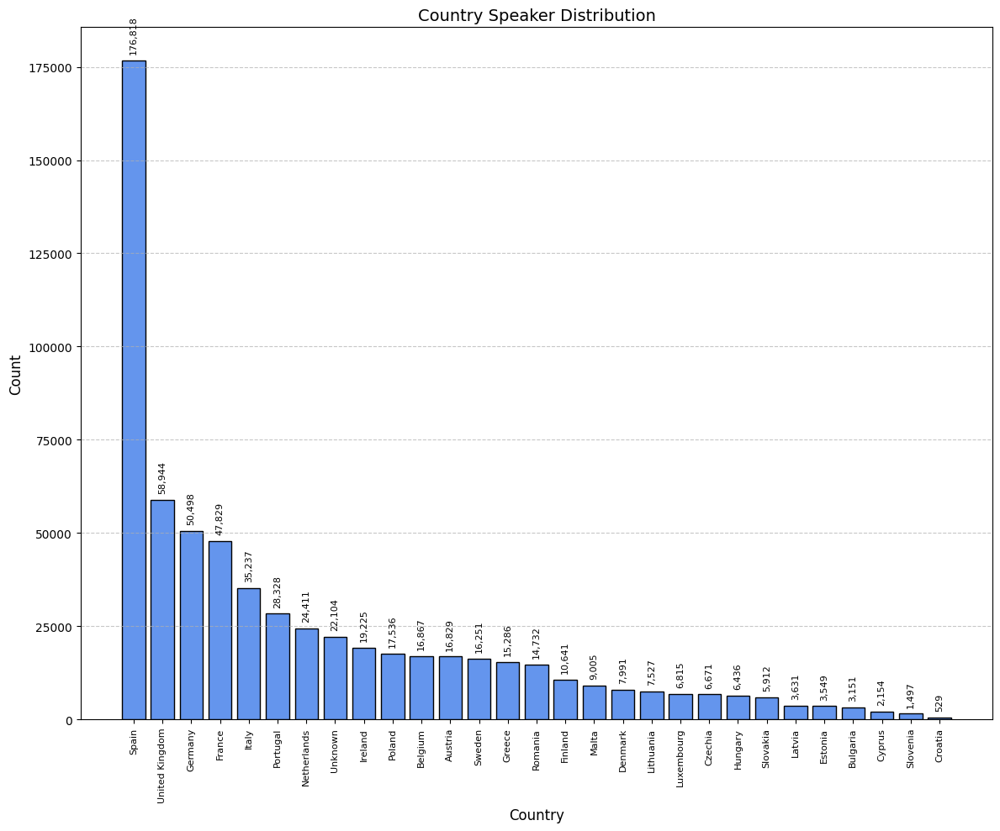

Total count: 636404


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Replace NaN with 'Unknown' so missing values are counted
data['speaker-country'] = data['speaker-country'].fillna('Unknown')

# Count the occurrences of each country
country_counts = data['speaker-country'].value_counts()

plt.figure(figsize=(12,10))

# Bar chart
bars = plt.bar(country_counts.index, country_counts.values,
               color='cornflowerblue', edgecolor='black')

# Add value labels above bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             yval + max(country_counts.values) * 0.01,  # spacing above bar
             f'{yval:,}', ha='center', va='bottom', fontsize=8, rotation=90)

# Title and labels
plt.title('Country Speaker Distribution', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, fontsize=8)  # Rotate labels to prevent overlap
plt.yticks(fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Total count:", sum(country_counts))

/tmp/ipython-input-592236810.py:29: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


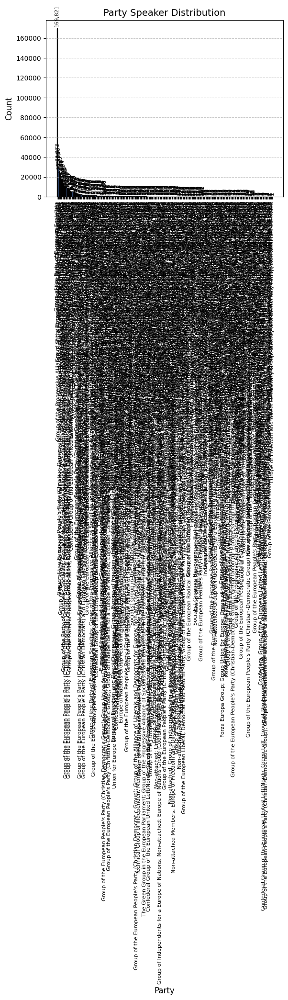

Total count: 636404


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Replace NaN with 'Unknown' so missing values are counted
data['detectedPoliticalGroupEU'] = data['detectedPoliticalGroupEU'].fillna('Unknown')

# Count the occurrences of each country
party_counts = data['detectedPoliticalGroupEU'].value_counts()

plt.figure(figsize=(12,10))

# Bar chart
bars = plt.bar(party_counts.index, party_counts.values,
               color='cornflowerblue', edgecolor='black')

# Add value labels above bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             yval + max(party_counts.values) * 0.01,  # spacing above bar
             f'{yval:,}', ha='center', va='bottom', fontsize=8, rotation=90)

# Title and labels
plt.title('Party Speaker Distribution', fontsize=14)
plt.xlabel('Party', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, fontsize=8)  # Rotate labels to prevent overlap
plt.yticks(fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Total count:", sum(party_counts))

/tmp/ipython-input-353783001.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


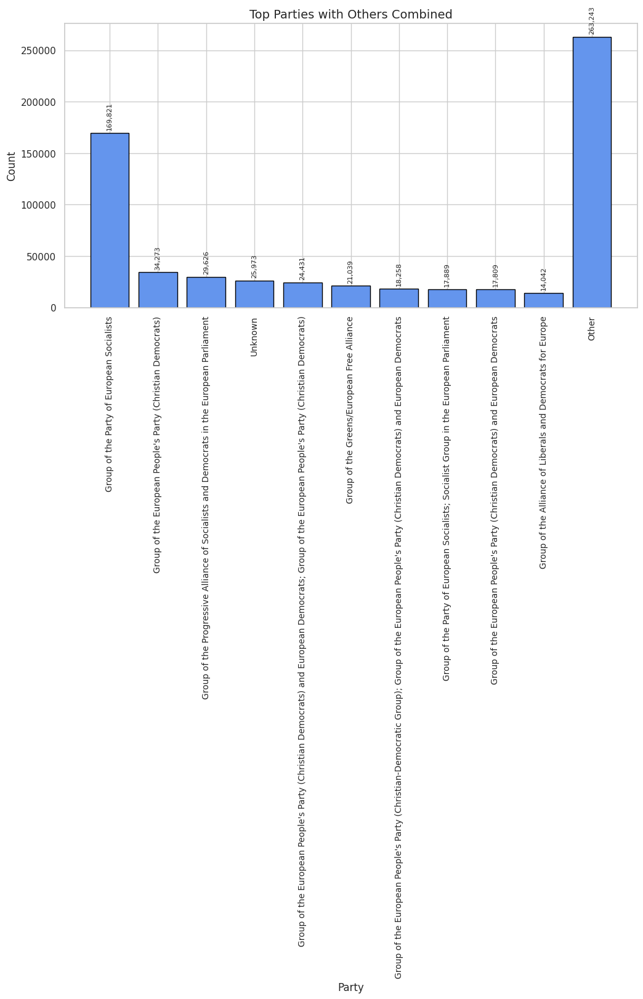

In [ ]:
top_n = 10
top_parties = party_counts.head(top_n)
other_count = party_counts.iloc[top_n:].sum()
top_parties['Other'] = other_count

plt.figure(figsize=(12,6))
bars = plt.bar(top_parties.index, top_parties.values, color='cornflowerblue', edgecolor='black')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + max(top_parties.values) * 0.01, f'{yval:,}', ha='center', va='bottom', fontsize=8, rotation=90)

plt.title('Top Parties with Others Combined', fontsize=14)
plt.xlabel('Party', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Filter for Bulgaria
bg_speeches = df[df['speaker-country'] == "Bulgaria"]

# Sort by publication date
bg_speeches_sorted = bg_speeches.sort_values(by="pubdate")

# Show earliest 10 speeches
bg_speeches_sorted.head(40)

,description,detectedmepid,detectedspeaker,docTitle,doctype,eventID,guid,language,link,parID,pubdate,seqID,source,speaker,speaker-title,title,wordcount,detectedNationalPoliticalGroup,detectedPoliticalGroupEU,speaker-country,TranslatedTitle,LanguageDetected,TranslatedDescription,interventionID,url,predicted_label,length,chunk_length,avg_evidence_score,avg_intuition_score,length_bin,evidence_mean,intuition_mean,evidence_adj,intuition_adj,evidence_z,intuition_z,evidence_minus_intuition_score,detectedspeaker_clean,year
15769,mohamed ali guengl – es mr president first of all i would like to congratulate mrs larive on her work in producing this report the civil service particularly the civil services of the member states must act as an example as regards applying community directives on equality bearing in mind the existence of recommendations community action programmes on equality the promotion of positive action for women the convention on the removal of discriminatory terms and resolutions both by parliament and by the united nations it is paradoxical that the real situation for women regarding employment and in this particular case even more unacceptably employment in the public service is still unequal we consider this resolution to be of the greatest importance because we think that despite the efforts made to establish equal working patterns the percentage of women civil servants working at c grade is still much higher than for,34250.0,Nedzhmi ALI,"Debates - Friday, 15 November 1996",epdebate,CRE-4-1996-11-15_EN,CRE-4-1996-11-15_EN-3e44d25e-87e6-4924-9c85-4567c052a22c,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-4-1996-11-15_EN.html', 'host': 'www.europarl.europa.eu'}",7.0,1996-11-15,7,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Mohamed Ali,GUE/NGL ES,6. Equal opportunities in the civil service,663.0,NaN,Group of the Alliance of Liberals and Democrats for Europe,Bulgaria,NaN,NaN,NaN,NaN,NaN,no,150,150,0.141712,0.092401,"(140, 150]",0.119585,0.093889,0.022127,-0.001488,0.435424,-0.027576,0.463000,nedzhmi ali,1996
15770,other grades particularly for grade a moreover women are not sufficiently represented in technical departments the need to formulate and improve current legislation must go hand in hand with the will to apply it in many cases the recommendations or measures to be applied are not binding and a wide margin of manoeuvre is left so that any progress achieved is minimal or simply nominal the concept of mainstreaming or the need to take equality into account in every area runs the risk of remaining a mere word if there is not attempt to put it into practice at every level in direct opposition to this concept are the budget cutbacks which affect in particular women in the civil service while fairly effective measures are being applied to deal with direct discrimination against women it is in relation to indirect discrimination that there is most resistance to change and which,34250.0,Nedzhmi ALI,"Debates - Friday, 15 November 1996",epdebate,CRE-4-1996-11-15_EN,CRE-4-1996-11-15_EN-3e44d25e-87e6-4924-9c85-4567c052a22c,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-4-1996-11-15_EN.html', 'host': 'www.europarl.europa.eu'}",7.0,1996-11-15,7,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Mohamed Ali,GUE/NGL ES,6. Equal opportunities in the civil service,663.0,NaN,Group of the Alliance of Liberals and Democrats for Europe,Bulgaria,NaN,NaN,NaN,NaN,NaN,no,150,150,0.112075,0.040289,"(140, 150]",0.119585,0.093889,-0.007511,-0.053600,-0.147796,-0.993480,0.845684,nedzhmi ali,1996
15771,requires rigorous application of positive action positive action is being challenged on the basis of the same argument of discrimination thus undermining any possibility of real change some of the measures regarded as positive such as parenta

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Filter for Bulgaria
cz_speeches = df[df['speaker-country'] == "Czechia"]

# Sort by publication date
cz_speeches_sorted = cz_speeches.sort_values(by="pubdate")

# Show earliest 10 speeches
cz_speeches_sorted.head(40)

,description,detectedmepid,detectedspeaker,docTitle,doctype,eventID,guid,language,link,parID,pubdate,seqID,source,speaker,speaker-title,title,wordcount,detectedNationalPoliticalGroup,detectedPoliticalGroupEU,speaker-country,TranslatedTitle,LanguageDetected,TranslatedDescription,interventionID,url,predicted_label,length,chunk_length,avg_evidence_score,avg_intuition_score,length_bin,evidence_mean,intuition_mean,evidence_adj,intuition_adj,evidence_z,intuition_z,evidence_minus_intuition_score,detectedspeaker_clean,year
106656,vaclav havelpresident of the czech republic1 – fr madam president members of the european parliament ladies and gentlemen the question of whether deep down a european has a sense of european identity alongside a sense or awareness of national identity crops up time and time again nowadays in other words do europeans really feel they are europeans or is it more of an abstract idea a theoretical concept designed to repackage a geographical factor as a state of mind this question also crops up during the debate on the degree of sovereignty which the nation states can and should transfer to the institutions of the european union some insist that if a clearlyfelt national identity is eclipsed too quickly by a european identity which few feel or which is even perceived as fanciful then things are sure to take a turn for the worse so what exactly do we mean,96714.0,Jiří HAVEL,"Debates - Wednesday, 16 February 2000",epdebate,CRE-5-2000-02-16_EN,CRE-5-2000-02-16_EN-f5a4a9dc-497f-44b1-83b5-d8ae1f50ef8e,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-5-2000-02-16_EN.html', 'host': 'www.europarl.europa.eu'}",12.0,2000-02-16,2,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Vaclav Havel,President of the Czech Republic FR,"12. Address by Mr Vaclav Havel, President of the Czech Republic",3617.0,NaN,Group of the Progressive Alliance of Socialists and Democrats in the European Parliament,Czechia,NaN,NaN,NaN,NaN,NaN,no,150,150,0.121581,0.196931,"(140, 150]",0.117213,0.092358,0.004368,0.104573,0.088189,1.979687,-1.891497,jiří havel,2000
106680,of the european structure in my view the fourth major mission which awaits europe is to try and show by its very existence that it is possible to counter the huge danger which our contradictory civilisation allows to hover over the planet i would be happy if my country could take part in all this as a fully paidup partner thank you for your attention long and enthusiastic standing ovation,96714.0,Jiří HAVEL,"Debates - Wednesday, 16 February 2000",epdebate,CRE-5-2000-02-16_EN,CRE-5-2000-02-16_EN-f5a4a9dc-497f-44b1-83b5-d8ae1f50ef8e,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-5-2000-02-16_EN.html', 'host': 'www.europarl.europa.eu'}",12.0,2000-02-16,2,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Vaclav Havel,President of the Czech Republic FR,"12. Address by Mr Vaclav Havel, President of the Czech Republic",3617.0,NaN,Group of the Progressive Alliance of Socialists and Democrats in the European Parliament,Czechia,NaN,NaN,NaN,NaN,NaN,no,70,70,0.093356,0.133883,"(60, 70]",0.109901,0.069336,-0.016545,0.064547,-0.334014,1.221945,-1.555958,jiří havel,2000
106679,the best spiritual tradition – the higher cosmic order as something which is above and beyond us and respect the moral order as the consequence of that higher order humility affability kindness respect for what we do not understand a deep feeling of solidarity with others respect for what is different the willingness to make sacrifices or do good deeds which eternity alone can reward the eternity which watches us silently through the eyes of our conscience these are the values which could and should be on the agenda as we construct europe europe bears all or some of the responsibility for the most horrific events of the 20th century 

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Filter for Bulgaria
es_speeches = df[df['speaker-country'] == "Estonia"]

# Sort by publication date
es_speeches_sorted = es_speeches.sort_values(by="pubdate")

# Show earliest 10 speeches
es_speeches_sorted.head(40)

,description,detectedmepid,detectedspeaker,docTitle,doctype,eventID,guid,language,link,parID,pubdate,seqID,source,speaker,speaker-title,title,wordcount,detectedNationalPoliticalGroup,detectedPoliticalGroupEU,speaker-country,TranslatedTitle,LanguageDetected,TranslatedDescription,interventionID,url,predicted_label,length,chunk_length,avg_evidence_score,avg_intuition_score,length_bin,evidence_mean,intuition_mean,evidence_adj,intuition_adj,evidence_z,intuition_z,evidence_minus_intuition_score,detectedspeaker_clean,year
157362,karlsson hans psesv mr president international trade is of central importance if conditions for growth and development are to be created throughout our world the rules governing this trade determine whether growth and development are to benefit the whole of humanity or are to be confined to the industrialised world mr désir’s report is an excellent instrument for bringing about something more akin to global justice in world trade the developing countries must be put on the same footing as the industrialised countries when it comes to participating in the joint work of the wto for me as a social democrat global justice is an end in itself the acts of terrorism in the united states also point to the need to limit the basis for hatred and fanaticism less injustice will increase the safety of us all the voluntary organisations must be given scope to express their opinions when,197131.0,Hannes HANSO,"Debates - Wednesday, 24 October 2001",epdebate,CRE-5-2001-10-24_EN,CRE-5-2001-10-24_EN-7748b6ca-4082-4173-83d1-9a9ee1bad500,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-5-2001-10-24_EN.html', 'host': 'www.europarl.europa.eu'}",7.0,2001-10-24,9,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Karlsson Hans,SV,7. International trade,242.0,NaN,Group of the Progressive Alliance of Socialists and Democrats in the European Parliament,Estonia,NaN,NaN,NaN,NaN,NaN,no,150,150,0.192254,0.206919,"(140, 150]",0.122977,0.102618,0.069278,0.104300,1.408361,1.998814,-0.590454,hannes hanso,2001
157363,world trade is discussed democracy can be deepened through the setting up of a parliamentary assembly within the wto social dumping must be prevented and employees’ rights must be provided for fundamental human rights must be respected the fight against environmental devastation intensified and child labour prohibited we must stop dumping our food surplus in the developing countries and instead give farmers in those countries a chance to increase their production and their opportunities to provide for themselves in that way we can make our contribution to a more just and more secure world,197131.0,Hannes HANSO,"Debates - Wednesday, 24 October 2001",epdebate,CRE-5-2001-10-24_EN,CRE-5-2001-10-24_EN-7748b6ca-4082-4173-83d1-9a9ee1bad500,en,"{'url': 'https://www.europarl.europa.eu/doceo/document/CRE-5-2001-10-24_EN.html', 'host': 'www.europarl.europa.eu'}",7.0,2001-10-24,9,"{'url': 'https://www.europarl.europa.eu/plenary/en/home.html', 'host': 'www.europarl.europa.eu', 'country': 'BE', 'id': 'europarl'}",Karlsson Hans,SV,7. International trade,242.0,NaN,Group of the Progressive Alliance of Socialists and Democrats in the European Parliament,Estonia,NaN,NaN,NaN,NaN,NaN,no,94,94,0.144654,0.148997,"(90, 100]",0.128355,0.103392,0.016298,0.045605,0.331331,0.873967,-0.542636,hannes hanso,2001
158975,karlsson hans psesv mr president europe needs a new strategy for dealing with the issues surrounding chemicals we are concerned here with the health of all of us as well as with that of future generations the commission’s white paper is a good point of departure for continued work on the strategy mrs schörling’s report creates good conditions for bringing about necessary changes it is exceptionally important that parliament adopt the report in such a form that it have the same thrust given to it by the rapporteur in the debate that took place while the 

# Plot

/tmp/ipython-input-779583543.py:6: DtypeWarning: Columns (17,20,21,22,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')


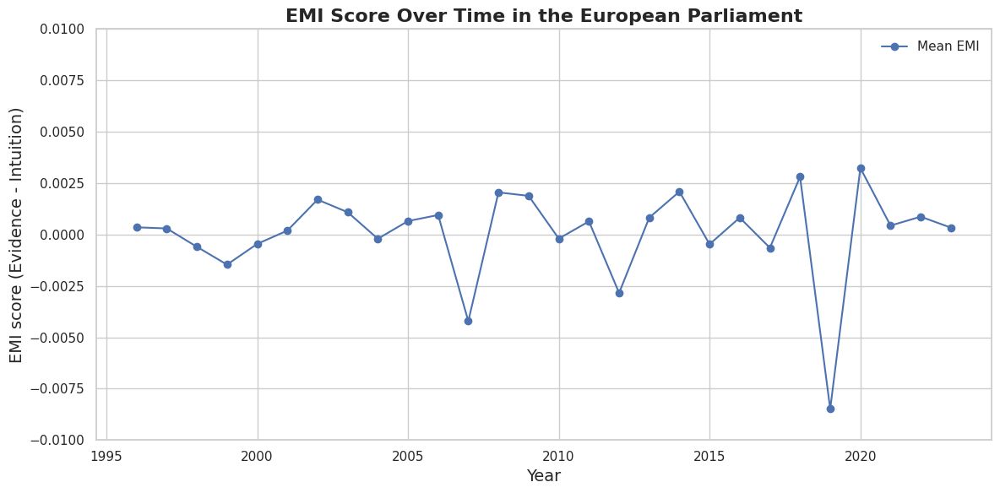

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === Load data ===
df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')

# === Process dates ===
df['pubdate'] = pd.to_datetime(df['pubdate'])
df['year'] = df['pubdate'].dt.year

# === Group by year and calculate mean ===
emi_summary = df.groupby('year')['evidence_minus_intuition_score'].mean().reset_index()

# === Plot ===
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))


# Line plot
plt.plot(emi_summary['year'], emi_summary['evidence_minus_intuition_score'],
         label='Mean EMI', color=sns.color_palette("deep")[0], marker='o')

# Make y-axis centered around zero
ymax = 0.01
plt.ylim(-ymax, ymax)

# Labels and layout
plt.title('EMI Score Over Time in the European Parliament', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=14)
plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
plt.grid(True, axis='x')
plt.legend(frameon=False)
plt.tight_layout()

# === Export as PNG ===
plt.savefig('/content/drive/MyDrive/gwenEU/emi_over_time_plot_centered_yaxis.png', dpi=300)

# Show plot
plt.show()

/tmp/ipython-input-1989776831.py:6: DtypeWarning: Columns (17,20,21,22,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')


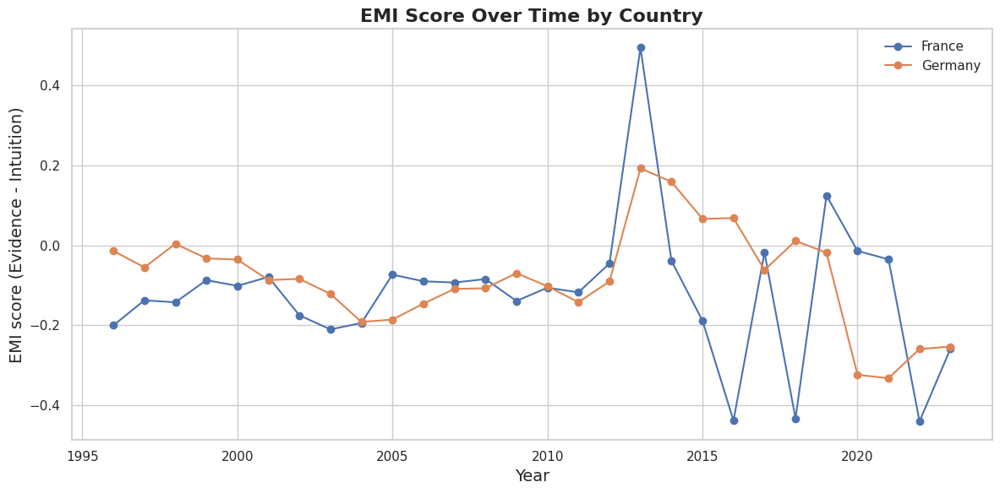

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === Load your dataset ===
df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip',low_memory=False)

# === Process dates ===
df['pubdate'] = pd.to_datetime(df['pubdate'], errors='coerce')
df['year'] = df['pubdate'].dt.year

# === Function to plot EMI for selected countries ===
def plot_emi_by_country(countries):
    # Filter for selected countries
    subset = df[df['speaker-country'].isin(countries)]

    # Group by year and country, compute mean EMI
    grouped = subset.groupby(['year', 'speaker-country'])['evidence_minus_intuition_score'] \
                    .mean().reset_index()

    # Plot
    plt.figure(figsize=(12, 6))
    sns.set(style="whitegrid")

    for country in countries:
        data_country = grouped[grouped['speaker-country'] == country]
        plt.plot(data_country['year'], data_country['evidence_minus_intuition_score'],
                 marker='o', label=country)

    plt.title(f"EMI Score Over Time by Country", fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
    plt.legend(frameon=False)
    plt.grid(True, axis='x')
    plt.tight_layout()
    plt.show()

# === Example usage ===
plot_emi_by_country(['France', 'Germany'])  # change this list to pick countries


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, SelectMultiple

# === Load your dataset ===
df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')
df['pubdate'] = pd.to_datetime(df['pubdate'], errors='coerce')
df['year'] = df['pubdate'].dt.year

# === Get unique countries sorted ===
countries_list = sorted(df['speaker-country'].dropna().unique())

# === Function to plot EMI for multiple selected countries ===
def plot_multiple_countries(selected_countries):
    if not selected_countries:
        print("Please select at least one country.")
        return

    sns.set(style="whitegrid")
    plt.figure(figsize=(12, 6))

    ymax = 0
    for country in selected_countries:
        subset = df[df['speaker-country'] == country]
        emi_summary = subset.groupby('year')['evidence_minus_intuition_score'].mean().reset_index()

        ymax = max(ymax, abs(emi_summary['evidence_minus_intuition_score']).max())
        plt.plot(emi_summary['year'], emi_summary['evidence_minus_intuition_score'],
                 marker='o', label=country)

    # Zero line and symmetric y-axis
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.ylim(-(1.2*ymax), 1.2*ymax)

    plt.title("EMI Score Over Time by Country", fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
    plt.grid(True, axis='x')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# === Interactive multi-select ===
interact(
    plot_multiple_countries,
    selected_countries=SelectMultiple(
        options=countries_list,
        description="Countries:",
        rows=10
    )
)

/tmp/ipython-input-3151050570.py:7: DtypeWarning: Columns (17,20,21,22,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')


interactive(children=(SelectMultiple(description='Countries:', options=('Austria', 'Belgium', 'Bulgaria', 'Cro…

<function __main__.plot_multiple_countries(selected_countries)>

In [ ]:
import pandas as pd

#df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')

# mapping dictionary
mapping = {
    # Far Left
    "Confederal Group of the European United Left - Nordic Green Left": "Far Left",
    "Confederal Group of the European United Left/Nordic Green Left": "Far Left",
    "The Left group in the European Parliament - GUE/NGL": "Far Left",
    "Group of the European United Left - Nordic Green Left": "Far Left",

    # Social Democrats
    "Group of the Party of European Socialists": "Social Democrats",
    "Socialist Group in the European Parliament": "Social Democrats",
    "Group of the Progressive Alliance of Socialists and Democrats in the European Parliament": "Social Democrats",

    # Greens / Regionalists
    "Group of the Greens/European Free Alliance": "Greens/EFA",
    "The Green Group in the European Parliament": "Greens/EFA",
    "Group of the European Radical Alliance": "Greens/EFA",  # when allied

    # Liberals / Centrists
    "Group of the European Liberal, Democrat and Reform Party": "Liberals/Renew",
    "Group of the Alliance of Liberals and Democrats for Europe": "Liberals/Renew",
    "Renew Europe Group": "Liberals/Renew",
    "Forza Europa Group": "Liberals/Renew",

    # Centre-Right EPP
    "Group of the European People's Party (Christian Democrats)": "EPP",
    "Group of the European People's Party (Christian Democrats) and European Democrats": "EPP",
    "Group of the European People's Party (Christian-Democratic Group)": "EPP",

    # Conservatives & Reformists
    "European Conservatives and Reformists Group": "ECR",
    "Union for Europe of the Nations Group": "ECR",

    # Right-Wing Nationalists / Eurosceptics
    "Identity and Democracy Group": "Far Right Eurosceptics",
    "Europe of Nations and Freedom Group": "Far Right Eurosceptics",
    "Europe of Freedom and Direct Democracy Group": "Far Right Eurosceptics",
    "Europe of freedom and democracy Group": "Far Right Eurosceptics",
    "Independence/Democracy Group": "Far Right Eurosceptics",
    "Group for a Europe of Democracies and Diversities": "Far Right Eurosceptics",
    "Group of Independents for a Europe of Nations": "Far Right Eurosceptics",
    "Patriots for Europe Group": "Far Right Eurosceptics",
    "Identity, Tradition and Sovereignty Group": "Far Right Eurosceptics",
    "Europe of Sovereign Nations Group": "Far Right Eurosceptics",

    # Technical / Mixed
    "Technical Group of Independent Members - mixed group": "Technical/Mixed",

    # Non-attached
    "Non-attached": "Non-attached",
    "Non-attached Members": "Non-attached",
}

# Apply mapping
def simplify_group(value):
    if pd.isna(value):
        return "Unknown"
    first_group = value.split(";")[0].strip()
    return mapping.get(first_group, "Other")

df["PoliticalGroupSimplified"] = df["detectedPoliticalGroupEU"].apply(simplify_group)

# Check result
print(df["PoliticalGroupSimplified"].value_counts())

# Save new file
df.to_csv("/content/drive/MyDrive/gwenEU/political_groups_simplified.csv", index=False)

PoliticalGroupSimplified
Social Democrats          262693
EPP                       153930
Liberals/Renew             54329
Greens/EFA                 35557
Far Left                   29750
Far Right Eurosceptics     26193
Unknown                    25973
Non-attached               19624
ECR                        16985
Other                      10370
Technical/Mixed             1000
Name: count, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, SelectMultiple

# load
df = pd.read_csv('/content/drive/MyDrive/gwenEU/political_groups_simplified.csv',low_memory=False)
df['pubdate'] = pd.to_datetime(df['pubdate'], errors='coerce')
df['year'] = df['pubdate'].dt.year

# === Get unique political groups sorted ===
parties_list = sorted(df['PoliticalGroupSimplified'].dropna().unique())

# === Define color mapping ===
color_map = {
    "Far Left": "#d73027",
    "Social Democrats": "#fc8d59",
    "Liberals/Renew": "#fee08b",
    "Greens/EFA": "#1a9850",
    "EPP": "#7570b3",
    "ECR": "#4575b4",
    "Right-Wing Eurosceptics": "#brown",
    "Non-attached": "#969696",
    "Technical/Mixed": "#525252",
    "Other": "#d9d9d9",
    "Unknown": "#cccccc"
}

# === Function to plot EMI for multiple selected political groups ===
def plot_multiple_parties(selected_parties):
    if not selected_parties:
        print("Please select at least one political group.")
        return

    sns.set(style="whitegrid")
    plt.figure(figsize=(12, 6))

    ymax = 0
    for party in selected_parties:
        subset = df[df['PoliticalGroupSimplified'] == party]
        emi_summary = subset.groupby('year')['evidence_minus_intuition_score'].mean().reset_index()

        ymax = max(ymax, abs(emi_summary['evidence_minus_intuition_score']).max())
        plt.plot(emi_summary['year'], emi_summary['evidence_minus_intuition_score'],
                 marker='o', label=party,
                 color=color_map.get(party, "black"))  # fallback to black if not mapped

    # Zero line and symmetric y-axis
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.ylim(-ymax, ymax)

    plt.title("EMI Score Over Time by Political Group", fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
    plt.grid(True, axis='x')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# === Interactive multi-select ===
interact(
    plot_multiple_parties,
    selected_parties=SelectMultiple(
        options=parties_list,
        description="Parties:",
        rows=10
    )
)


interactive(children=(SelectMultiple(description='Parties:', options=('ECR', 'EPP', 'Far Left', 'Far Right Eur…

<function __main__.plot_multiple_parties(selected_parties)>

#Final plots

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, SelectMultiple
import numpy as np

# load
df = pd.read_csv('/content/drive/MyDrive/gwenEU/political_groups_simplified.csv')
df['pubdate'] = pd.to_datetime(df['pubdate'], errors='coerce')
df['year'] = df['pubdate'].dt.year

# === Get unique political groups sorted ===
parties_list = sorted(df['PoliticalGroupSimplified'].dropna().unique())

# === Improved color mapping with nicer shades ===
color_map = {
    "Far Left": "#d73027",
    "Social Democrats": "#fc8d59",
    "Liberals/Renew": "#fee08b",
    "Greens/EFA": "#1a9850",
    "EPP": "#7570b3",
    "ECR": "#4575b4",
    "Right-Wing Eurosceptics": "#8c510a",
    "Non-attached": "#969696",
    "Technical/Mixed": "#525252",
    "Other": "#d9d9d9",
    "Unknown": "#cccccc"
}

# === Function to plot EMI for multiple selected political groups ===
def plot_multiple_parties(selected_parties):
    if not selected_parties:
        print("Please select at least one political group.")
        return

    sns.set(style="whitegrid")
    plt.figure(figsize=(12, 6))

    ymax = 0
    for party in selected_parties:
        subset = df[df['PoliticalGroupSimplified'] == party]
        emi_summary = subset.groupby('year')['evidence_minus_intuition_score'].agg(['mean', 'count', 'std']).reset_index()
        emi_summary['sem'] = emi_summary['std'] / np.sqrt(emi_summary['count'])

        ymax = max(ymax, abs(emi_summary['mean']).max() + emi_summary['sem'].max())

        plt.errorbar(
            emi_summary['year'],
            emi_summary['mean'],
            yerr=emi_summary['sem'],
            label=party,
            marker='o',
            capsize=3,
            color=color_map.get(party, "black")
        )

    # Zero line and symmetric y-axis
    plt.xticks([1994, 1999, 2004, 2009, 2014, 2019, 2024])
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.ylim(-ymax, ymax)

    plt.title("EMI Score Over Time by Political Group", fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
    plt.grid(True, axis='x')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# === Interactive multi-select ===
interact(
    plot_multiple_parties,
    selected_parties=SelectMultiple(
        options=parties_list,
        description="Parties:",
        rows=10
    )
)

/tmp/ipython-input-3039747654.py:8: DtypeWarning: Columns (17,20,21,22,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/gwenEU/political_groups_simplified.csv')


interactive(children=(SelectMultiple(description='Parties:', options=('ECR', 'EPP', 'Far Left', 'Far Right Eur…

<function __main__.plot_multiple_parties(selected_parties)>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, SelectMultiple
import numpy as np

# === Load your dataset ===
df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')
df['pubdate'] = pd.to_datetime(df['pubdate'], errors='coerce')
df['year'] = df['pubdate'].dt.year

# === Get unique countries sorted ===
countries_list = sorted(df['speaker-country'].dropna().unique())

# === Function to plot EMI for multiple selected countries with error bars ===
def plot_multiple_countries(selected_countries):
    if not selected_countries:
        print("Please select at least one country.")
        return

    sns.set(style="whitegrid")
    plt.figure(figsize=(12, 6))

    ymax = 0
    for country in selected_countries:
        subset = df[df['speaker-country'] == country]

        # compute mean, std, count → SEM
        emi_summary = subset.groupby('year')['evidence_minus_intuition_score'].agg(['mean','std','count']).reset_index()
        emi_summary['sem'] = emi_summary['std'] / np.sqrt(emi_summary['count'])

        ymax = max(ymax, (abs(emi_summary['mean']).max() + emi_summary['sem'].max()))

        plt.errorbar(
            emi_summary['year'],
            emi_summary['mean'],
            yerr=emi_summary['sem'],
            marker='o',
            capsize=3,
            label=country
        )

    # Zero line and symmetric y-axis
    plt.xticks([1994, 1999, 2004, 2009, 2014, 2019, 2024])
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.ylim(-(1.2*ymax), 1.2*ymax)

    plt.title("EMI Score Over Time by Country", fontsize=16, fontweight='bold')
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('EMI score (Evidence - Intuition)', fontsize=14)
    plt.grid(True, axis='x')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# === Interactive multi-select ===
interact(
    plot_multiple_countries,
    selected_countries=SelectMultiple(
        options=countries_list,
        description="Countries:",
        rows=10
    )
)

/tmp/ipython-input-48707777.py:8: DtypeWarning: Columns (17,20,21,22,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/gwenEU/outputv2_filled.csv.gzip', compression='gzip')


interactive(children=(SelectMultiple(description='Countries:', options=('Austria', 'Belgium', 'Bulgaria', 'Cro…

<function __main__.plot_multiple_countries(selected_countries)>